# 1. Exploratory Data Analysis (EDA)

This section explores the AI4I 2020 Predictive Maintenance dataset to understand its structure, assess data quality, and identify characteristics that may influence the machine learning workflow.

The analysis focuses on dataset structure, feature and target definition, target distribution, missing values, and data types.

In [1]:
import pandas as pd

data=pd.read_csv("ai4i2020.csv")

x = data[["Type","Air temperature [K]","Process temperature [K]","Rotational speed [rpm]","Torque [Nm]","Tool wear [min]"]]
y = data["Machine failure"]

## 1.1. Dataset Overview

This subsection examines the dataset's dimensions, initial observations, and overall structure.

The objective is to understand the available variables and determine whether the dataset requires any initial data quality checks before further analysis.

In [2]:
x.shape,y.shape

((10000, 6), (10000,))

In [3]:
data.head()

,UDI,Product ID,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
0,1,M14860,M,298.1,308.6,1551,42.8,0,0,0,0,0,0,0
1,2,L47181,L,298.2,308.7,1408,46.3,3,0,0,0,0,0,0
2,3,L47182,L,298.1,308.5,1498,49.4,5,0,0,0,0,0,0
3,4,L47183,L,298.2,308.6,1433,39.5,7,0,0,0,0,0,0
4,5,L47184,L,298.2,308.7,1408,40.0,9,0,0,0,0,0,0


In [4]:
data.dtypes

UDI                          int64
Product ID                  object
Type                        object
Air temperature [K]        float64
Process temperature [K]    float64
Rotational speed [rpm]       int64
Torque [Nm]                float64
Tool wear [min]              int64
Machine failure              int64
TWF                          int64
HDF                          int64
PWF                          int64
OSF                          int64
RNF                          int64
dtype: object

In [5]:
data.describe()

,UDI,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
count,10000.00000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.00000
mean,5000.50000,300.004930,310.005560,1538.776100,39.986910,107.951000,0.033900,0.004600,0.011500,0.009500,0.009800,0.00190
std,2886.89568,2.000259,1.483734,179.284096,9.968934,63.654147,0.180981,0.067671,0.106625,0.097009,0.098514,0.04355
min,1.00000,295.300000,305.700000,1168.000000,3.800000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000
25%,2500.75000,298.300000,308.800000,1423.000000,33.200000,53.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000
50%,5000.50000,300.100000,310.100000,1503.000000,40.100000,108.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000
75%,7500.25000,301.500000,311.100000,1612.000000,46.800000,162.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000
max,10000.00000,304.500000,313.800000,2886.000000,76.600000,253.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.00000


<Axes: ylabel='Type'>

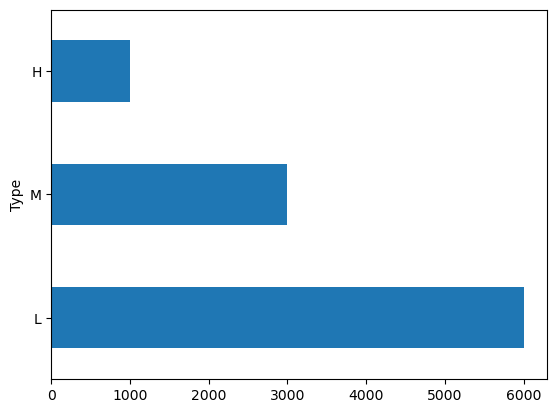

In [6]:
data["Type"].value_counts().plot(kind="barh")

## 1.2. Data Types and Feature Types

The data types of the dataset columns are examined to distinguish numerical variables from categorical variables and identifiers.

This information will guide the preprocessing strategy, including categorical encoding where necessary and any scaling required by the selected machine learning algorithms.

In [7]:
x.head()

,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min]
0,M,298.1,308.6,1551,42.8,0
1,L,298.2,308.7,1408,46.3,3
2,L,298.1,308.5,1498,49.4,5
3,L,298.2,308.6,1433,39.5,7
4,L,298.2,308.7,1408,40.0,9


In [8]:
y.dtypes

dtype('int64')

In [9]:
x.dtypes

Type                        object
Air temperature [K]        float64
Process temperature [K]    float64
Rotational speed [rpm]       int64
Torque [Nm]                float64
Tool wear [min]              int64
dtype: object

After examining the data types of the features, we found that the `Type` feature is stored as an object data type and contains categorical values. To prepare the dataset for machine learning, we will apply an appropriate encoding technique to convert these categorical values into a numerical representation.

## 1.3. Target Distribution and Class Imbalance

The distribution of the target variable is examined to determine the proportion of failure and non-failure observations.

Class imbalance is important because a model may achieve high accuracy by favoring the majority class while failing to identify a substantial proportion of actual failures.

Therefore, model performance will be evaluated using additional metrics, including precision, recall, F1-score, and average precision, rather than relying on accuracy alone.

<Axes: ylabel='Machine failure'>

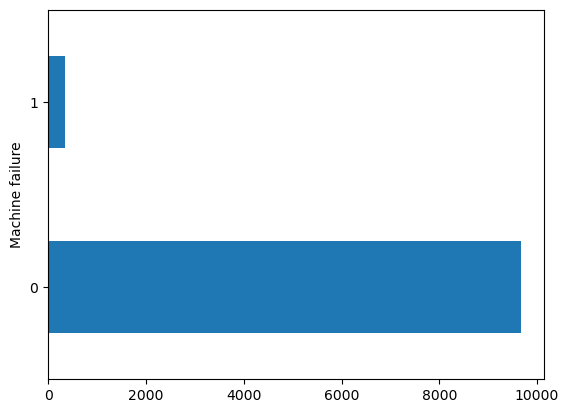

In [10]:
y.value_counts().plot(kind='barh')

In [11]:
y.value_counts(normalize=True)*100

Machine failure
0    96.61
1     3.39
Name: proportion, dtype: float64

## 1.4. Missing Values Analysis

Missing values are checked across all dataset columns to assess whether any imputation or missing-data handling is required.

The results of this analysis will determine whether a missing-value treatment step is necessary during preprocessing.

In [12]:
x.isna().sum()

Type                       0
Air temperature [K]        0
Process temperature [K]    0
Rotational speed [rpm]     0
Torque [Nm]                0
Tool wear [min]            0
dtype: int64

In [13]:
y.isna().sum()

np.int64(0)

In [14]:
data.isna().sum()

UDI                        0
Product ID                 0
Type                       0
Air temperature [K]        0
Process temperature [K]    0
Rotational speed [rpm]     0
Torque [Nm]                0
Tool wear [min]            0
Machine failure            0
TWF                        0
HDF                        0
PWF                        0
OSF                        0
RNF                        0
dtype: int64

**Finding:** No missing values were detected in the dataset. Therefore, missing-value imputation is not required based on this check.

## 1.5 Modeling Pipeline Strategy

A consistent preprocessing and modeling workflow will be used to ensure reliable and reproducible experiments.



In [15]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OrdinalEncoder,StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer

x_train,x_test,y_train,y_test=train_test_split(x,y,test_size=0.2,random_state=42,stratify=y)

num_feature=["Air temperature [K]","Process temperature [K]","Rotational speed [rpm]","Torque [Nm]","Tool wear [min]"]
cat_faeture=["Type"]

num_pipe=Pipeline([
    ("scale",StandardScaler())
])

cat_pipe=Pipeline([
    ("encoded",OrdinalEncoder())
])

preprocessor=ColumnTransformer([
    ("numeric",num_pipe,num_feature),
    ("categorical",cat_pipe,cat_faeture)
])

# 2. Model Training and Experimentation

This notebook focuses on training multiple machine learning classifiers to predict machine failures using the AI4I 2020 Predictive Maintenance dataset.

Each model is trained using a pipeline that combines the required preprocessing steps with the classification algorithm. This approach helps maintain a consistent workflow across experiments and reduces the risk of inconsistent preprocessing.

The following models are explored:

- Logistic Regression
- Random Forest
- Support Vector Machine (SVM)
- Naive Bayes
- AdaBoost
- Gradient Boosting


## 2.1 Logistic Regression

In [16]:
from sklearn.linear_model import LogisticRegression

log_pipe=Pipeline([
("process",preprocessor),
("model",LogisticRegression(random_state=42))
])

## 2.2 Random Forest

In [17]:
from sklearn.ensemble import RandomForestClassifier

forest_pipe=Pipeline([
    ("pre",preprocessor),
    ("model",RandomForestClassifier(random_state=42,n_estimators=200))
])

## 2.3 Support Vector Machine (SVM)

In [18]:
from sklearn.svm import SVC

svm_pipe=Pipeline([
    ("pre",preprocessor),
    ("model",SVC(kernel="rbf",probability=True,class_weight="balanced"))
])


## 2.4 Naive Bayes

In [19]:
from sklearn.naive_bayes import GaussianNB

bayes_pipe=Pipeline([
    ("pre",preprocessor),
    ("model",GaussianNB())
])

## 2.5 Gradient Boosting & AdaBoost

In [20]:
from sklearn.ensemble import GradientBoostingClassifier,AdaBoostClassifier

gb_pipe=Pipeline([
    ("pre",preprocessor),
    ("model",GradientBoostingClassifier())
])

ada_pipe=Pipeline([
    ("pre",preprocessor),
    ("model",AdaBoostClassifier())
])


# 3.Threshold Selection and Model Comparison

In this section, cross-validated predicted probabilities are used to examine the relationship between precision and recall at different classification thresholds.

For each model, a threshold is selected based on the smallest absolute difference between precision and recall. The corresponding precision, recall, and accuracy scores are then calculated and collected in a comparison table.

The plots visualize how precision and recall change with the threshold and highlight the selected threshold for each model.

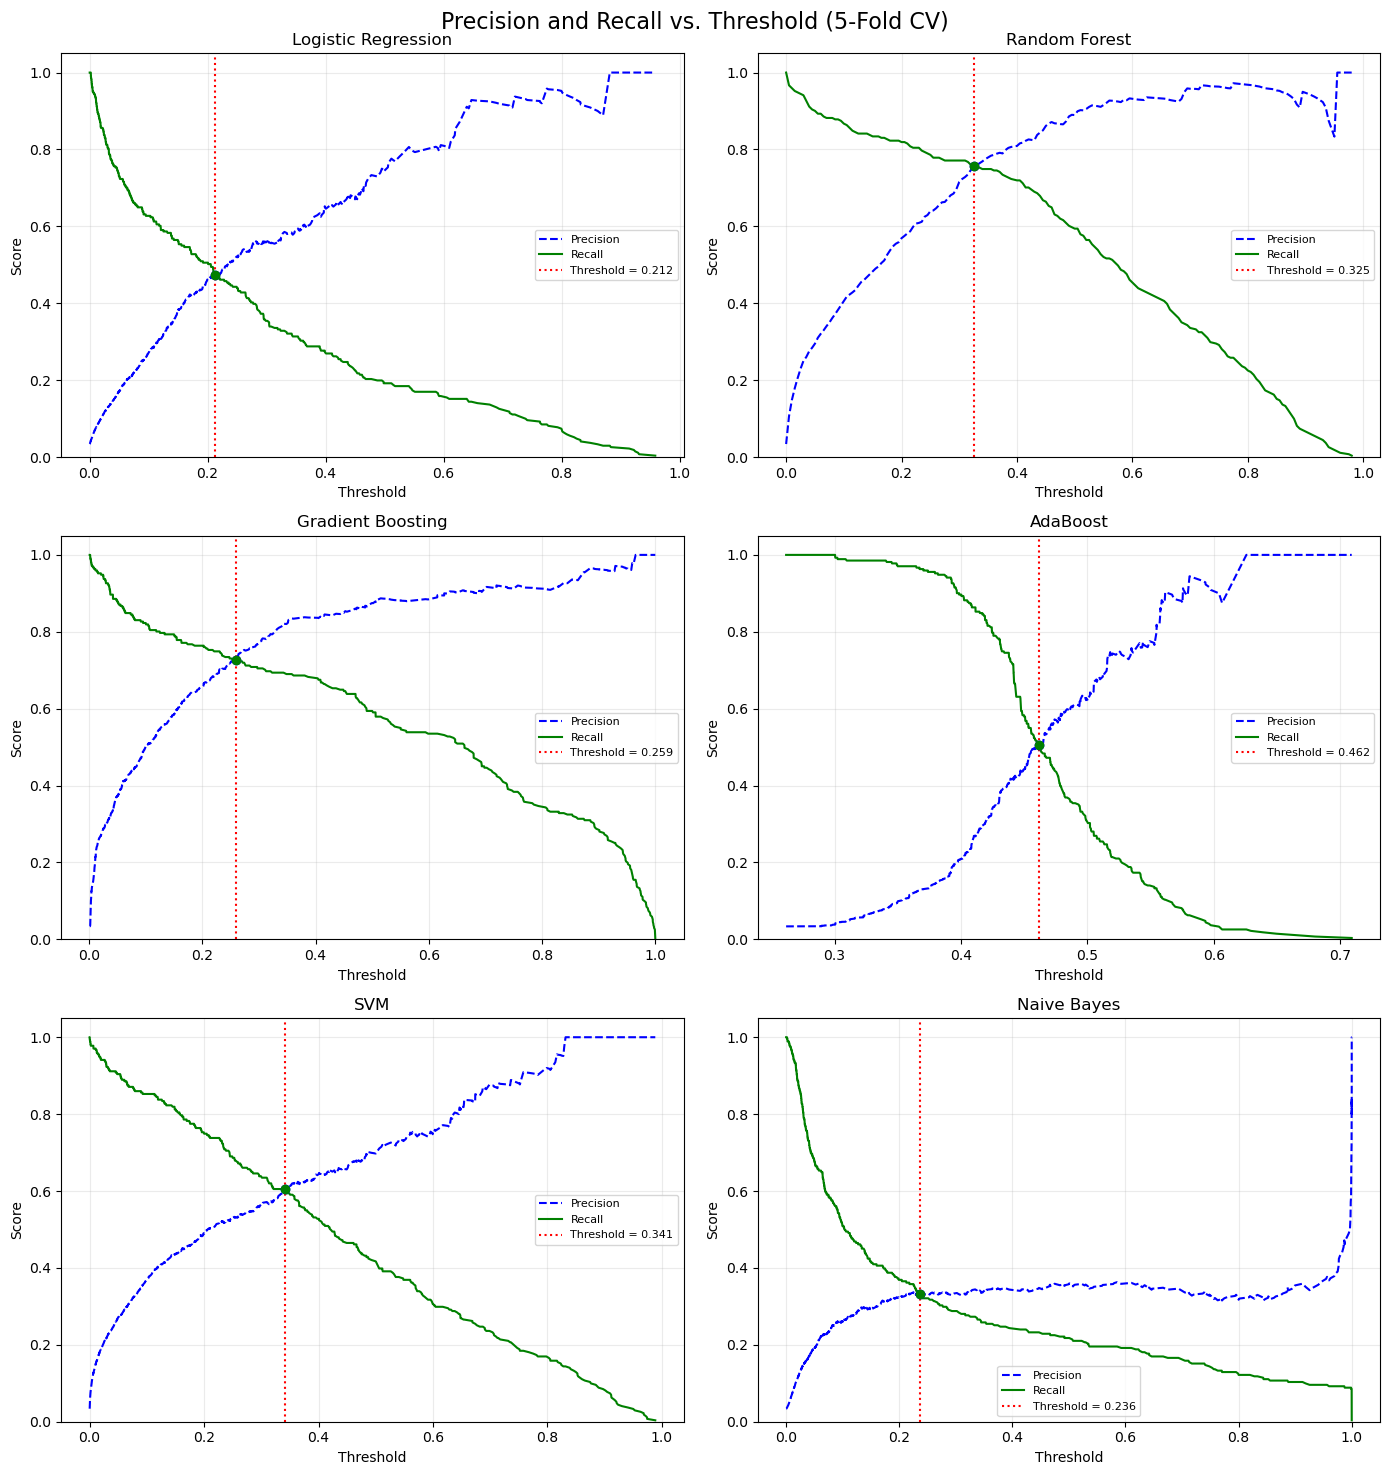

In [22]:
from sklearn.model_selection import cross_val_score,cross_val_predict
from sklearn.metrics import precision_score,recall_score,accuracy_score,precision_recall_curve
import matplotlib.pyplot as plt
import numpy as np
from sklearn.metrics import (
    accuracy_score,
    precision_recall_curve
)

results = []

models = [
    ("Logistic Regression", log_pipe),
    ("Random Forest", forest_pipe),
    ("Gradient Boosting", gb_pipe),
    ("AdaBoost", ada_pipe),
    ("SVM", svm_pipe),
    ("Naive Bayes", bayes_pipe)
]

fig, axes = plt.subplots(3, 2, figsize=(14, 15))
axes = axes.flatten()

for i, (model_name, model) in enumerate(models):
    y_proba_cv = cross_val_predict(
        model,
        x_train,
        y_train.squeeze(),
        cv=5,
        method="predict_proba"
    )[:, 1]

    precisions, recalls, pr_thresholds = precision_recall_curve(
        y_train.squeeze(),
        y_proba_cv
    )

    diff = np.abs(precisions[:-1] - recalls[:-1])
    best_idx = np.argmin(diff)

    threshold = pr_thresholds[best_idx]
    precision = precisions[best_idx]
    recall = recalls[best_idx]

    y_pred_best = (y_proba_cv >= threshold).astype(int)
    accuracy = accuracy_score(y_train.squeeze(), y_pred_best)

    results.append({
        "Model": model_name,
        "Best Threshold": threshold,
        "Accuracy": accuracy,
        "Precision": precision,
        "Recall": recall
    })

    ax = axes[i]

    ax.plot(pr_thresholds, precisions[:-1], "b--", label="Precision")
    ax.plot(pr_thresholds, recalls[:-1], "g-", label="Recall")
    ax.axvline(
        threshold,
        color="red",
        linestyle=":",
        label=f"Threshold = {threshold:.3f}"
    )

    ax.scatter(threshold, precision, color="blue", zorder=5)
    ax.scatter(threshold, recall, color="green", zorder=5)

    ax.set_title(model_name)
    ax.set_xlabel("Threshold")
    ax.set_ylabel("Score")
    ax.set_ylim(0, 1.05)
    ax.grid(alpha=0.25)
    ax.legend(fontsize=8)

fig.suptitle(
    "Precision and Recall vs. Threshold (5-Fold CV)",
    fontsize=16
)
fig.tight_layout()
plt.show()

comparison = pd.DataFrame(results).round(4)

### Comparison of Classification Models

The following table summarizes the selected threshold and the corresponding accuracy, precision, and recall for each candidate model.

These results provide an initial comparison of model performance and the trade-offs between precision and recall. The results are based on cross-validated predictions from the training data and should not be considered final test-set performance.

In [23]:
comparison

,Model,Best Threshold,Accuracy,Precision,Recall
0,Logistic Regression,0.2119,0.9642,0.4723,0.4723
1,Random Forest,0.3250,0.9835,0.7565,0.7565
2,Gradient Boosting,0.2586,0.9815,0.7269,0.7269
3,AdaBoost,0.4621,0.9665,0.5055,0.5055
4,SVM,0.3414,0.9732,0.6052,0.6052
5,Naive Bayes,0.2360,0.9548,0.3321,0.3321
